
# Exploratory Data Analysis of House Prices

## Project Overview

The objective of this project is to perform Exploratory Data Analysis (EDA) on the Ames Housing Dataset.

The project focuses on understanding different factors that affect house sale prices. We will analyse numerical and categorical data, calculate statistical measures, identify missing values and outliers, and create visualizations.

## Dataset Description

The dataset contains information about houses, including their area, quality, neighborhood, year of construction, and sale price.

## Objectives

1. Understand the distribution of house prices.
2. Identify features correlated with SalePrice.
3. Analyse the effect of overall quality on house prices.
4. Compare house prices across neighborhoods.
5. Detect outliers and missing values.
6. Create visualizations and a final dashboard.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!



## 1. Data Loading

In this section, we upload the Ames Housing Dataset and load it using Pandas. We will use the dataset to perform exploratory data analysis.


In [2]:

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [3]:

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



## 2. Data Understanding

In this section, we will examine the dataset, understand its structure, identify data types and check for missing values.


In [4]:

print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()


Dataset Shape:
(1460, 81)

First 5 Rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

In [5]:

missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing_percentage = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})

display(missing_table)
print("Total columns with missing values:", len(missing))


,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


Total columns with missing values: 19



### Observation

The dataset contains approximately 1460 rows and 81 columns. It includes numerical and categorical information about houses. Some columns contain missing values, which need to be examined before further analysis.



## 3. Variable Classification

In this section, we classify the columns into numerical, categorical and ordinal variables based on their data types and meaning.


In [6]:

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nNumber of Numerical Columns:", len(numeric_cols))
print("Number of Categorical Columns:", len(categorical_cols))


Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Fireplac

In [7]:

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column, order in ordinal_map.items():
    df[column] = pd.Categorical(
        df[column],
        categories=order,
        ordered=True
    )

print("Ordinal variables identified successfully!")
print("OverallQual is also an ordinal variable (1 to 10).")


Ordinal variables identified successfully!
OverallQual is also an ordinal variable (1 to 10).


In [8]:

variable_summary = []

for col in df.columns:
    if col in ["OverallQual", "ExterQual", "KitchenQual"]:
        variable_type = "Ordinal"
    elif col in numeric_cols:
        variable_type = "Numerical"
    else:
        variable_type = "Categorical"

    variable_summary.append({
        "Column": col,
        "Type": variable_type,
        "Unique Values": df[col].nunique(),
        "Example Values": str(df[col].dropna().unique()[:3])
    })

variable_table = pd.DataFrame(variable_summary)

display(variable_table.head(20))


,Column,Type,Unique Values,Example Values
0,Id,Numerical,1460,[1 2 3]
1,MSSubClass,Numerical,15,[60 20 70]
2,MSZoning,Categorical,5,['RL' 'RM' 'C (all)']
3,LotFrontage,Numerical,110,[65. 80. 68.]
4,LotArea,Numerical,1073,[ 8450 9600 11250]
5,Street,Categorical,2,['Pave' 'Grvl']
6,Alley,Categorical,2,['Grvl' 'Pave']
7,LotShape,Categorical,4,['Reg' 'IR1' 'IR2']
8,LandContour,Categorical,4,['Lvl' 'Bnk' 'Low']
9,Utilities,Categorical,2,['AllPub' 'NoSeWa']



### Observation

The dataset contains numerical, categorical and ordinal variables. Numerical variables include SalePrice and GrLivArea. Categorical variables include Neighborhood and HouseStyle. OverallQual is an ordinal variable because it represents house quality on a scale from 1 to 10.



## 4. Descriptive Statistics

Descriptive statistics help us understand the central values and spread of the dataset. We will calculate different statistical measures for SalePrice, GrLivArea and LotArea.


In [9]:

display(df.describe())


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [10]:

columns = ["SalePrice", "GrLivArea", "LotArea"]

for col in columns:
    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())



Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [11]:

print("Neighborhood Value Counts:")
display(df["Neighborhood"].value_counts())

print("\nHouseStyle Value Counts:")
display(df["HouseStyle"].value_counts())

print("\nNeighborhood Mode:", df["Neighborhood"].mode()[0])
print("HouseStyle Mode:", df["HouseStyle"].mode()[0])


Neighborhood Value Counts:


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



HouseStyle Value Counts:


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8



Neighborhood Mode: NAmes
HouseStyle Mode: 1Story



print("Neighborhood Value Counts:")
display(df["Neighborhood"].value_counts())

print("\nHouseStyle Value Counts:")
display(df["HouseStyle"].value_counts())

print("\nNeighborhood Mode:", df["Neighborhood"].mode()[0])
print("HouseStyle Mode:", df["HouseStyle"].mode()[0])



## 5. Data Cleaning

In this section, we will check duplicate records, handle missing values, standardize categorical values and identify impossible values.


In [12]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)


Number of duplicate rows: 0
Dataset Shape After Removing Duplicates: (1460, 81)


In [13]:

# Columns where missing values mean the feature is absent

absent_columns = [
    "PoolQC", "Alley", "Fence",
    "FireplaceQu", "GarageType"
]

for col in absent_columns:
    df[col] = df[col].fillna("None")

# Fill other categorical missing values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

# Fill remaining numerical missing values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing values handled successfully!")


Missing values handled successfully!


In [14]:

print("Total Missing Values:", df.isnull().sum().sum())

display(df.isnull().sum().sort_values(ascending=False).head(10))


Total Missing Values: 0


,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,0
LotArea,0
Street,0
Alley,0
LotShape,0
LandContour,0
Utilities,0


In [15]:

print("Houses built after the year of sale:")
display(df[df["YearBuilt"] > df["YrSold"]])

print("Negative LotArea values:", (df["LotArea"] < 0).sum())
print("Negative GrLivArea values:", (df["GrLivArea"] < 0).sum())


Houses built after the year of sale:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


Negative LotArea values: 0
Negative GrLivArea values: 0



### Observation

Duplicate records were checked and removed if present. Missing values were handled using suitable methods. Some missing categorical values represent the absence of a feature rather than unknown information. Numerical missing values were filled using the median.



## 6. Univariate Analysis

Univariate analysis studies one variable at a time. We will examine the distribution of SalePrice, house quality and house styles using different graphs.


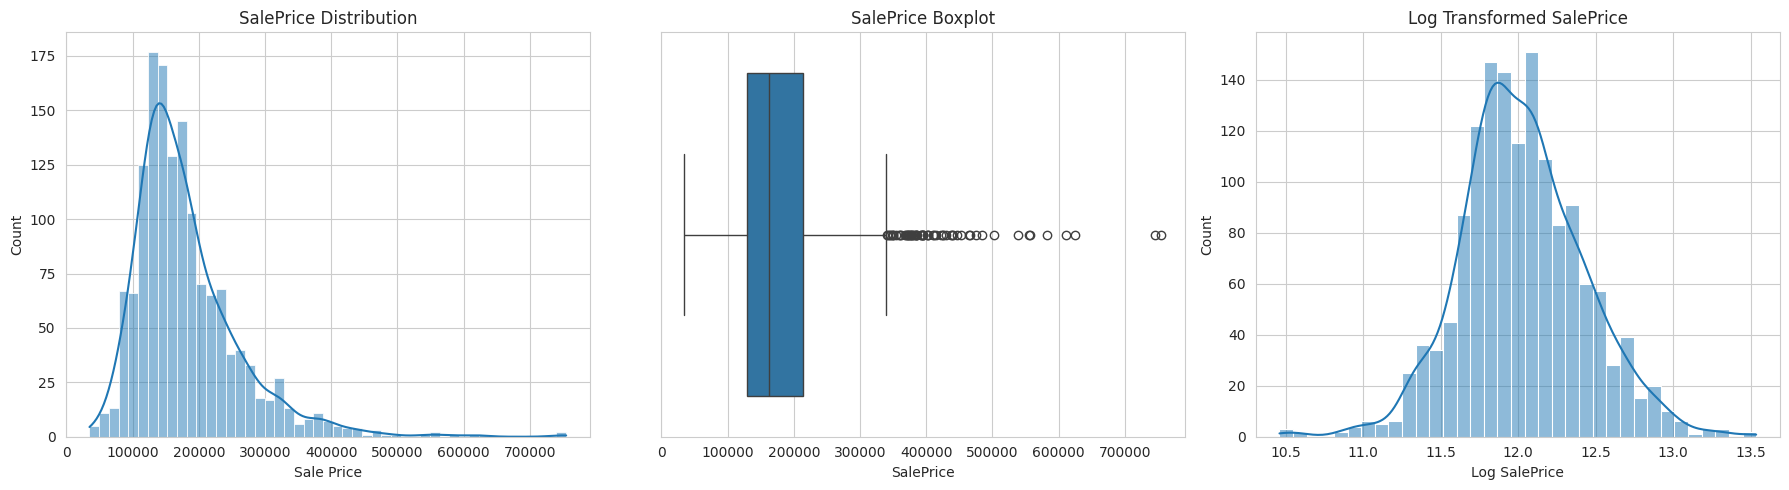

Original Skewness: 1.8828757597682129
Log Skewness: 0.12134661989685333


In [16]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram with KDE
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price")

# Boxplot
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")

# Log transformed histogram
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log Transformed SalePrice")
axes[2].set_xlabel("Log SalePrice")

plt.tight_layout()
plt.show()

print("Original Skewness:", df["SalePrice"].skew())
print("Log Skewness:", np.log1p(df["SalePrice"]).skew())


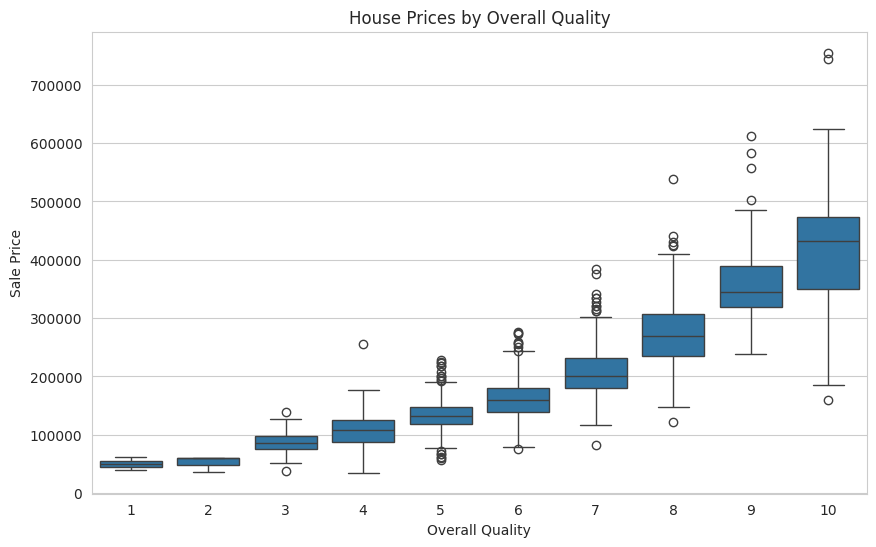

In [17]:

plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="OverallQual", y="SalePrice")

plt.title("House Prices by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()


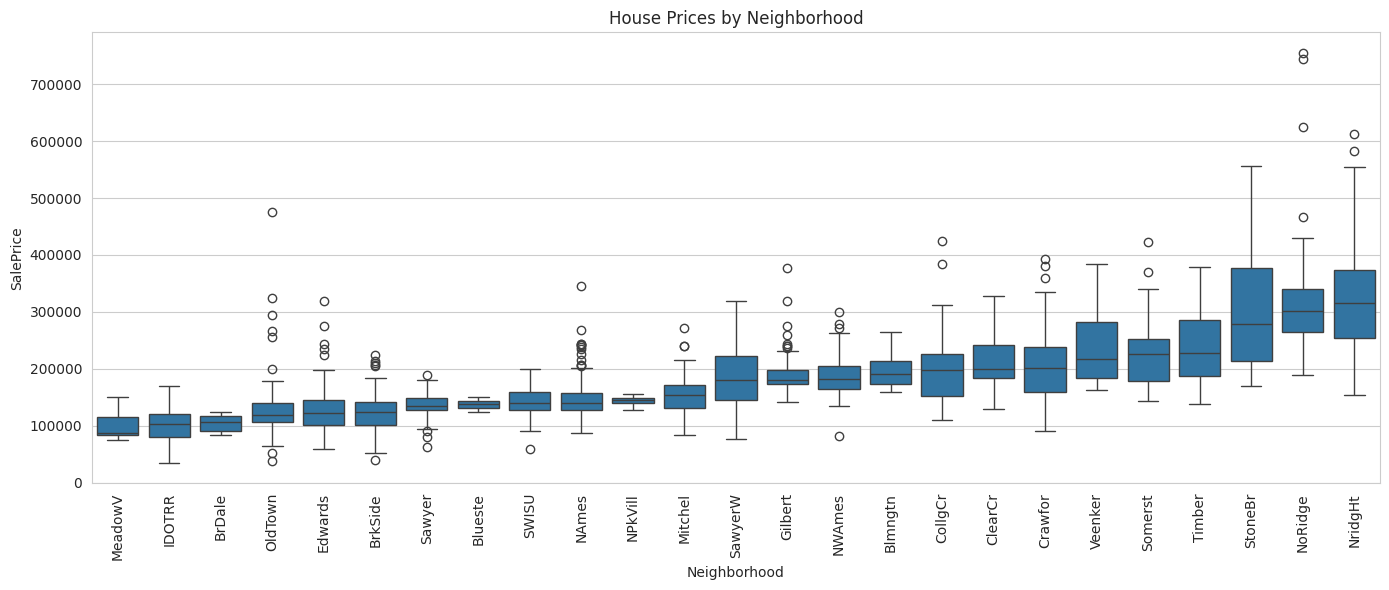

In [18]:

neighborhood_order = (
    df.groupby("Neighborhood", observed=True)["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice",
    order=neighborhood_order
)

plt.title("House Prices by Neighborhood")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


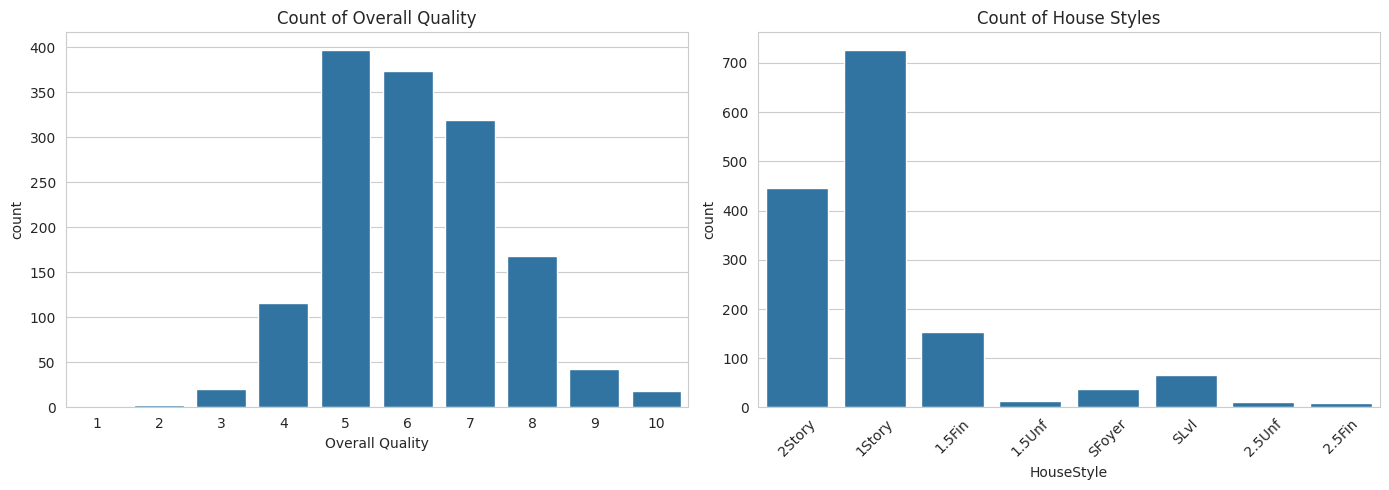

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="OverallQual", ax=axes[0])
axes[0].set_title("Count of Overall Quality")
axes[0].set_xlabel("Overall Quality")

sns.countplot(data=df, x="HouseStyle", ax=axes[1])
axes[1].set_title("Count of House Styles")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



### Observation

The SalePrice distribution shows how house prices are spread across the dataset. The histogram and skewness values help us identify whether the distribution is symmetrical or skewed. The boxplot helps identify unusual price values. We can also compare prices across different quality levels and neighborhoods.



## 7. Correlation and Covariance

Correlation measures the strength and direction of the relationship between two numerical variables. Covariance shows how two variables change together.


In [20]:

numeric_data = df.select_dtypes(include=np.number).drop(
    columns=["Id"], errors="ignore"
)

corr_matrix = numeric_data.corr()
cov_matrix = numeric_data.cov()

print("Correlation Matrix:")
display(corr_matrix)

print("Covariance Matrix:")
display(cov_matrix)


Correlation Matrix:


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1.000000,-0.356718,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.023573,-0.069836,-0.065649,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.356718,1.000000,0.304522,0.234812,-0.053281,0.116685,0.083348,0.178469,0.214367,0.042463,...,0.075542,0.137014,0.010287,0.061945,0.037655,0.180819,-0.000255,0.010451,0.006380,0.334771
LotArea,-0.139781,0.304522,1.000000,0.105806,-0.005636,0.014228,0.013788,0.103321,0.214103,0.111170,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,0.032628,0.234812,0.105806,1.000000,-0.091932,0.572323,0.550684,0.407252,0.239666,-0.059119,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,-0.059316,-0.053281,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.125694,-0.046231,0.040229,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,0.027850,0.116685,0.014228,0.572323,-0.375983,1.000000,0.592855,0.311600,0.249503,-0.049107,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,0.040581,0.083348,0.013788,0.550684,0.073741,0.592855,1.000000,0.176529,0.128451,-0.067759,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,0.023573,0.178469,0.103321,0.407252,-0.125694,0.311600,0.176529,1.000000,0.261256,-0.071330,...,0.159991,0.122528,-0.109907,0.019144,0.062248,0.011928,-0.029512,-0.006723,-0.008317,0.472614
BsmtFinSF1,-0.069836,0.214367,0.214103,0.239666,-0.046231,0.249503,0.128451,0.261256,1.000000,-0.050117,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420
BsmtFinSF2,-0.065649,0.042463,0.111170,-0.059119,0.040229,-0.049107,-0.067759,-0.071330,-0.050117,1.000000,...,0.067898,0.003093,0.036543,-0.029993,0.088871,0.041709,0.004940,-0.015211,0.031706,-0.011378


Covariance Matrix:


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1789.338306,-332.383444,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.802163e+02,-1.347356e+03,-447.979166,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-332.383444,485.218558,6.695349e+04,7.153368,-1.306036,7.763077e+01,37.904239,7.104999e+02,2.153695e+03,150.892607,...,2.085659e+02,1.999667e+02,13.849807,40.003775,46.248205,160.026746,-2.790734,0.622386,0.186659,5.858268e+05
LotArea,-59017.418634,66953.487175,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.863827e+05,9.746908e+05,179002.233638,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,1.908771,7.153368,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.017930e+02,1.511770e+02,-13.189617,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,-2.792117,-1.306036,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.527922e+01,-2.346427e+01,7.221779,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,35.581337,77.630770,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.700904e+03,3.437028e+03,-239.263730,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,35.439934,37.904239,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.586785e+02,1.209533e+03,-225.669866,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,180.216291,710.499868,1.863827e+05,101.793021,-25.279221,1.700904e+03,658.678517,3.266383e+04,2.153566e+04,-2079.647658,...,3.624210e+03,1.467221e+03,-1214.046712,101.434517,627.277297,86.615646,-2646.215645,-3.285160,-1.996226,6.785682e+06
BsmtFinSF1,-1347.355751,2153.694521,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.153566e+04,2.080255e+05,-3687.508609,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07
BsmtFinSF2,-447.979166,150.892607,1.790022e+05,-13.189617,7.221779,-2.392637e+02,-225.669866,-2.079648e+03,-3.687509e+03,26023.907779,...,1.372874e+03,3.305446e+01,360.306240,-141.852290,799.374305,270.331980,395.351466,-6.634118,6.792848,-1.458175e+05


In [21]:

top_corr = (
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Features Correlated with SalePrice:")
display(top_corr)

print("\nActual Correlation Values:")
display(corr_matrix.loc[top_corr.index, "SalePrice"])


Top 10 Features Correlated with SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101



Actual Correlation Values:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [22]:

top3 = top_corr.index[:3]

for col in top3:
    print("\nFeature:", col)
    print("Correlation with SalePrice:",
          corr_matrix.loc[col, "SalePrice"])
    print("Covariance with SalePrice:",
          cov_matrix.loc[col, "SalePrice"])



Feature: OverallQual
Correlation with SalePrice: 0.7909816005838053
Covariance with SalePrice: 86904.12583679947

Feature: GrLivArea
Correlation with SalePrice: 0.7086244776126515
Covariance with SalePrice: 29581866.743236605

Feature: GarageCars
Correlation with SalePrice: 0.6404091972583519
Covariance with SalePrice: 38020.18135897171



### Observation

Correlation helps identify features that have a strong relationship with SalePrice. Its values range from -1 to +1, making comparisons easier. Covariance depends on the units of the variables, so it is harder to compare directly. Correlation does not necessarily mean causation.



## 8. Scatter Plots and Pair Plots

Scatter plots help us understand relationships between two numerical variables. Pair plots allow us to examine multiple relationships together.


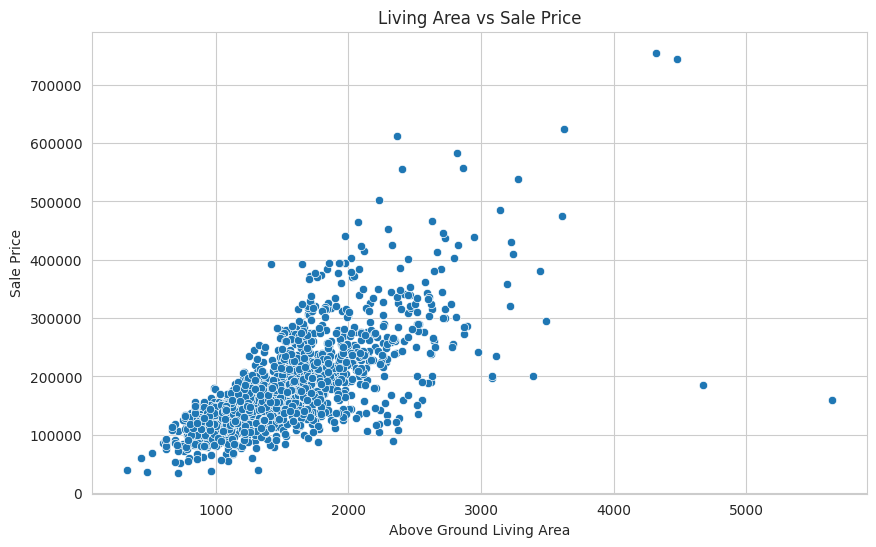

In [23]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")

plt.show()


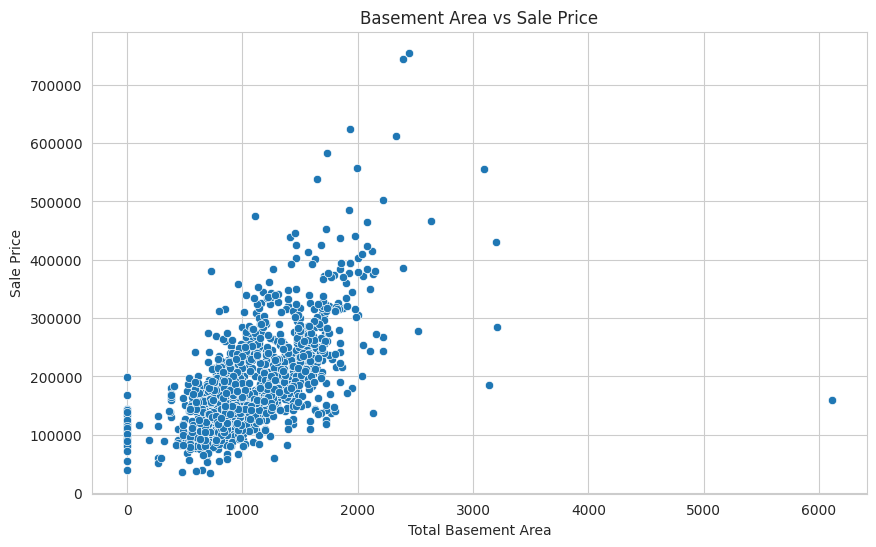

In [24]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="TotalBsmtSF",
    y="SalePrice"
)

plt.title("Basement Area vs Sale Price")
plt.xlabel("Total Basement Area")
plt.ylabel("Sale Price")

plt.show()


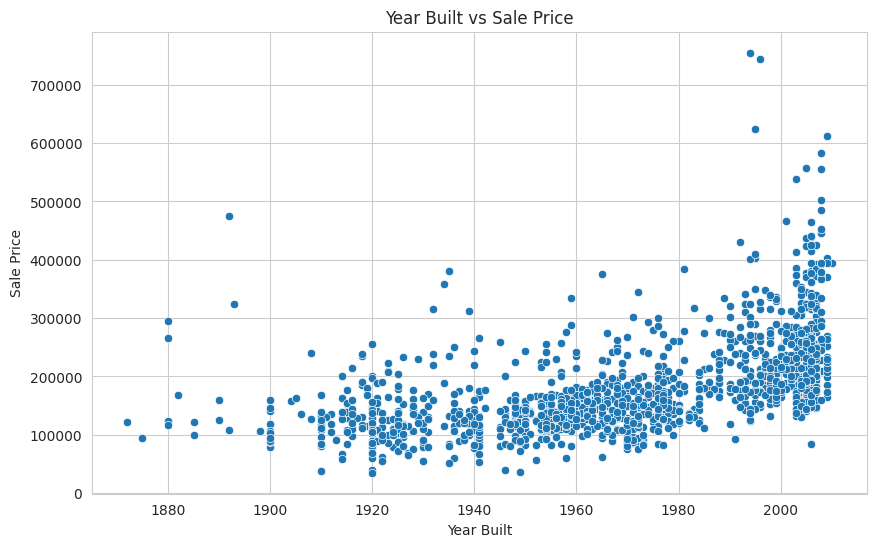

In [25]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice"
)

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()


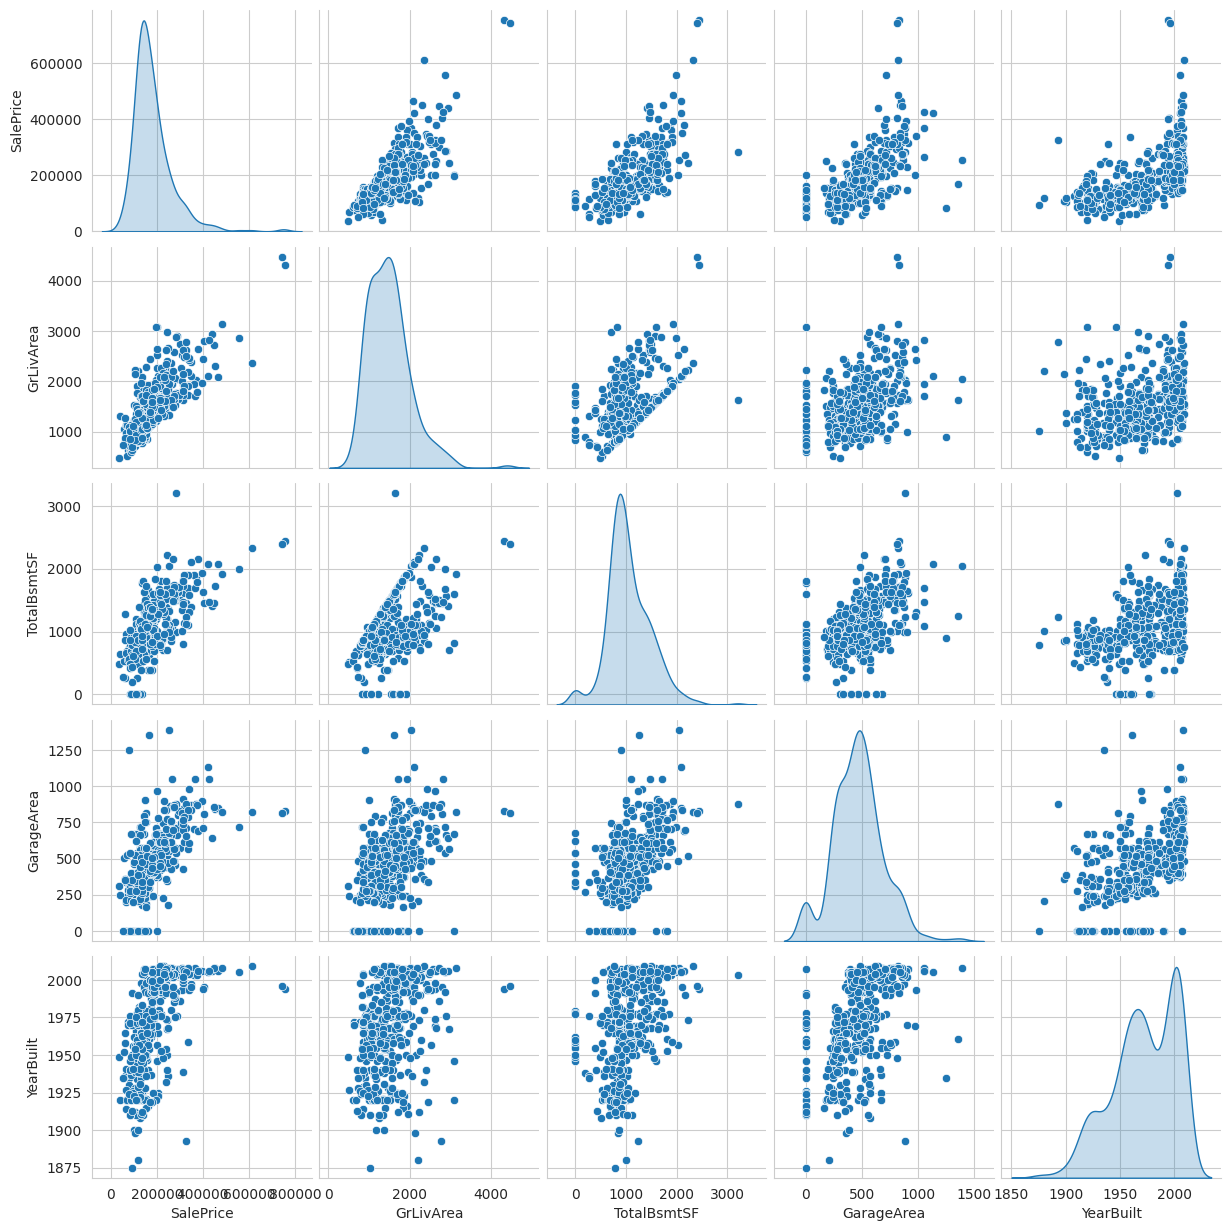

In [26]:

selected = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(
    df[selected].sample(
        n=min(500, len(df)),
        random_state=42
    ),
    diag_kind="kde"
)

plt.show()



### Observation

Scatter plots help us understand how living area, basement area and construction year are related to house prices. Pair plots show relationships between multiple numerical features. Generally, larger living areas tend to be associated with higher house prices.



## 9. Correlation Heatmap

A correlation heatmap provides a visual representation of relationships between numerical variables. It helps identify positively and negatively correlated features.


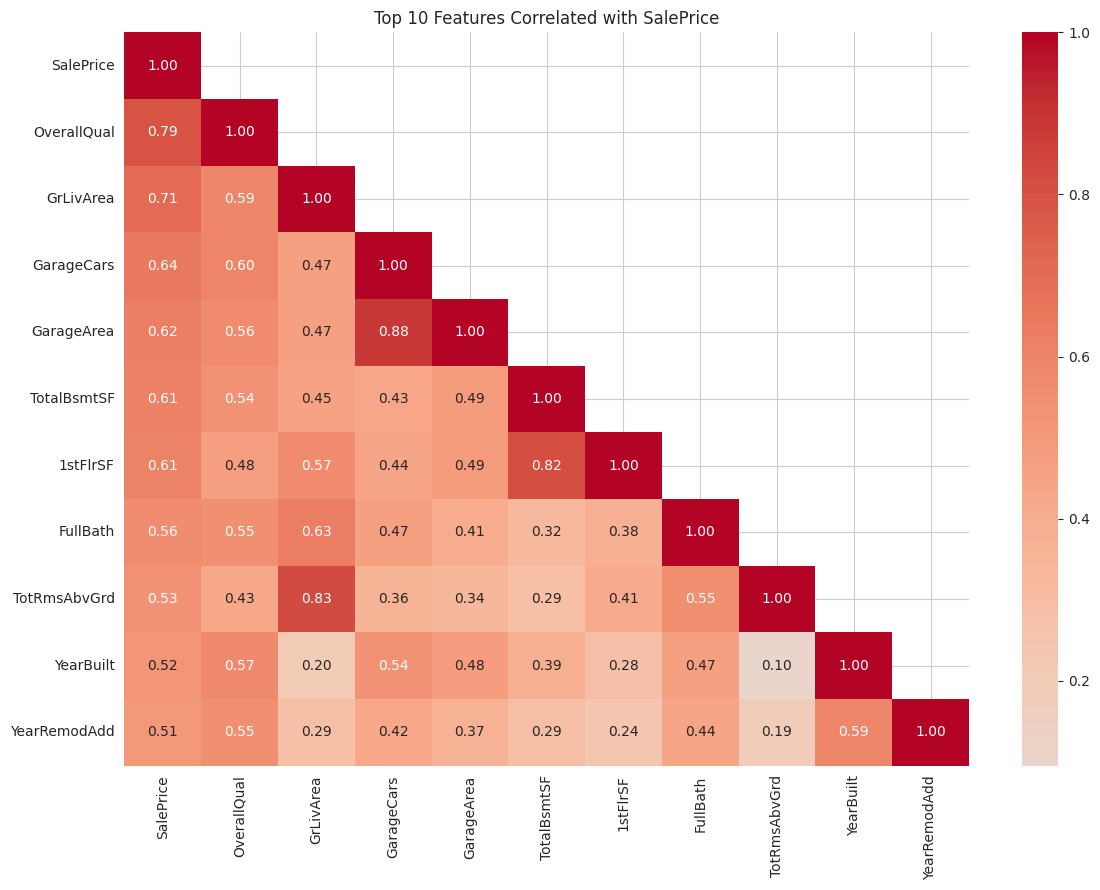

In [27]:

top10_features = [
    "SalePrice"
] + top_corr.index.tolist()

corr_top = numeric_data[top10_features].corr()

mask = np.triu(
    np.ones_like(corr_top, dtype=bool),
    k=1
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_top,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()



### Observation

The heatmap displays the correlation between the top features related to SalePrice. Values closer to +1 indicate a strong positive relationship, while values closer to -1 indicate a strong negative relationship. Values near zero indicate a weak linear relationship.



## 10. Outlier Detection

In this section, we identify outliers using the IQR method and Z-score method. We will compare the results to understand unusual house prices and living areas.


In [28]:

def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)]

print("IQR Outliers in GrLivArea:",
      len(iqr_outliers(df["GrLivArea"])))

print("IQR Outliers in SalePrice:",
      len(iqr_outliers(df["SalePrice"])))


IQR Outliers in GrLivArea: 31
IQR Outliers in SalePrice: 61


In [29]:

def zscore_outliers(series, threshold=3):
    z = np.abs(stats.zscore(series))
    return series[z > threshold]

print("Z-score Outliers in GrLivArea:",
      len(zscore_outliers(df["GrLivArea"])))

print("Z-score Outliers in SalePrice:",
      len(zscore_outliers(df["SalePrice"])))


Z-score Outliers in GrLivArea: 16
Z-score Outliers in SalePrice: 22


In [30]:

for col in ["GrLivArea", "SalePrice"]:

    iqr_result = iqr_outliers(df[col])
    z_result = zscore_outliers(df[col])

    print("\nColumn:", col)
    print("IQR Outliers:", len(iqr_result))
    print("Z-score Outliers:", len(z_result))
    print("Common Outliers:", len(
        set(iqr_result.index) & set(z_result.index)
    ))



Column: GrLivArea
IQR Outliers: 31
Z-score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-score Outliers: 22
Common Outliers: 22


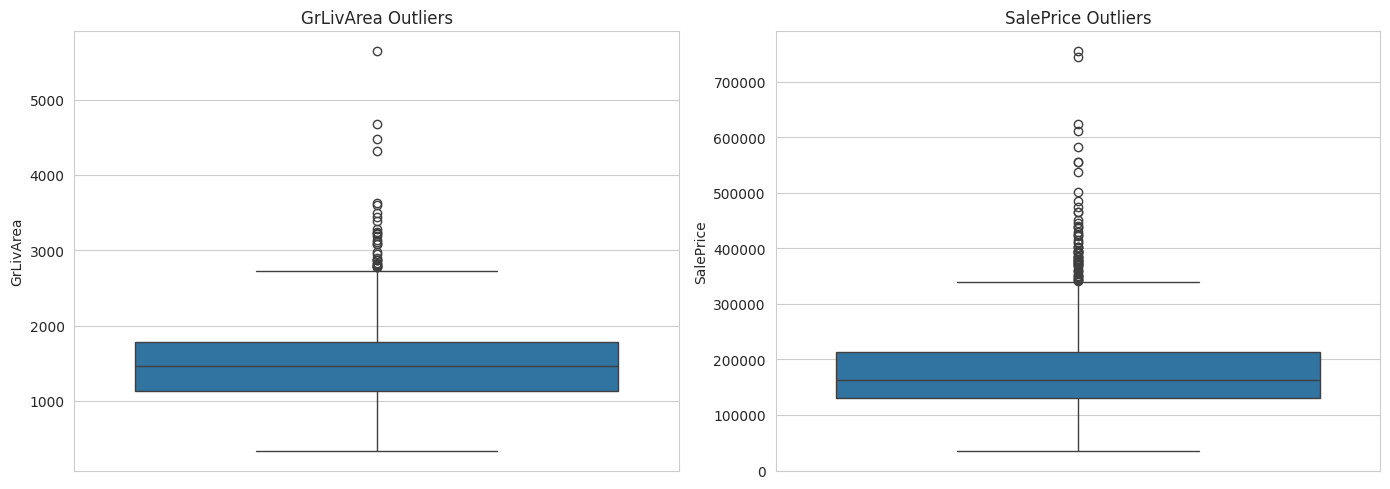

In [31]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea Outliers")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outliers")

plt.tight_layout()
plt.show()


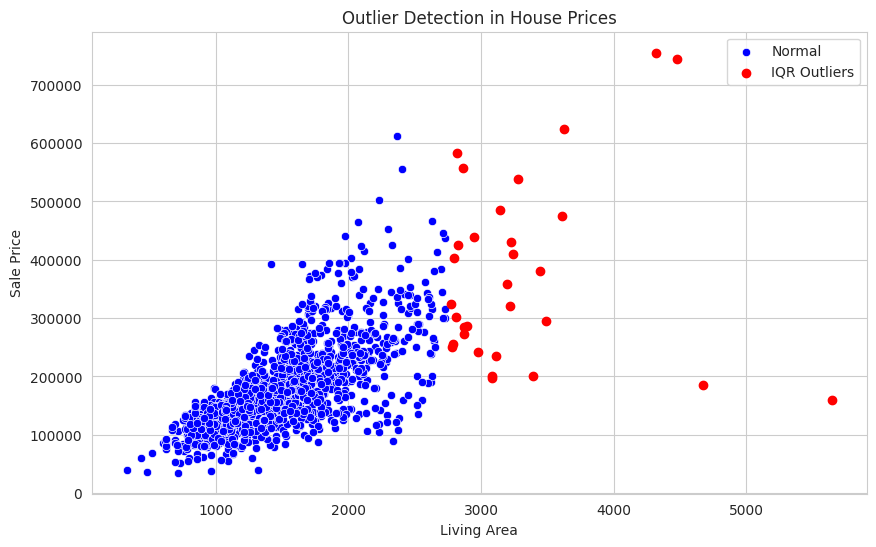

In [32]:

outlier_index = set(iqr_outliers(df["GrLivArea"]).index)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    color="blue",
    label="Normal"
)

outlier_df = df.loc[list(outlier_index)]

plt.scatter(
    outlier_df["GrLivArea"],
    outlier_df["SalePrice"],
    color="red",
    label="IQR Outliers"
)

plt.title("Outlier Detection in House Prices")
plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.legend()

plt.show()



### Observation

The IQR and Z-score methods identify unusual values using different approaches. IQR uses quartiles, while Z-score uses the mean and standard deviation. On skewed data, IQR may identify more outliers than Z-score. Outliers should not automatically be removed because some may represent genuine house sales.



## 11. Final Dashboard

The final dashboard combines important visualizations to summarize the analysis of house prices. It includes a line plot, bar plot, histogram and scatter plot.


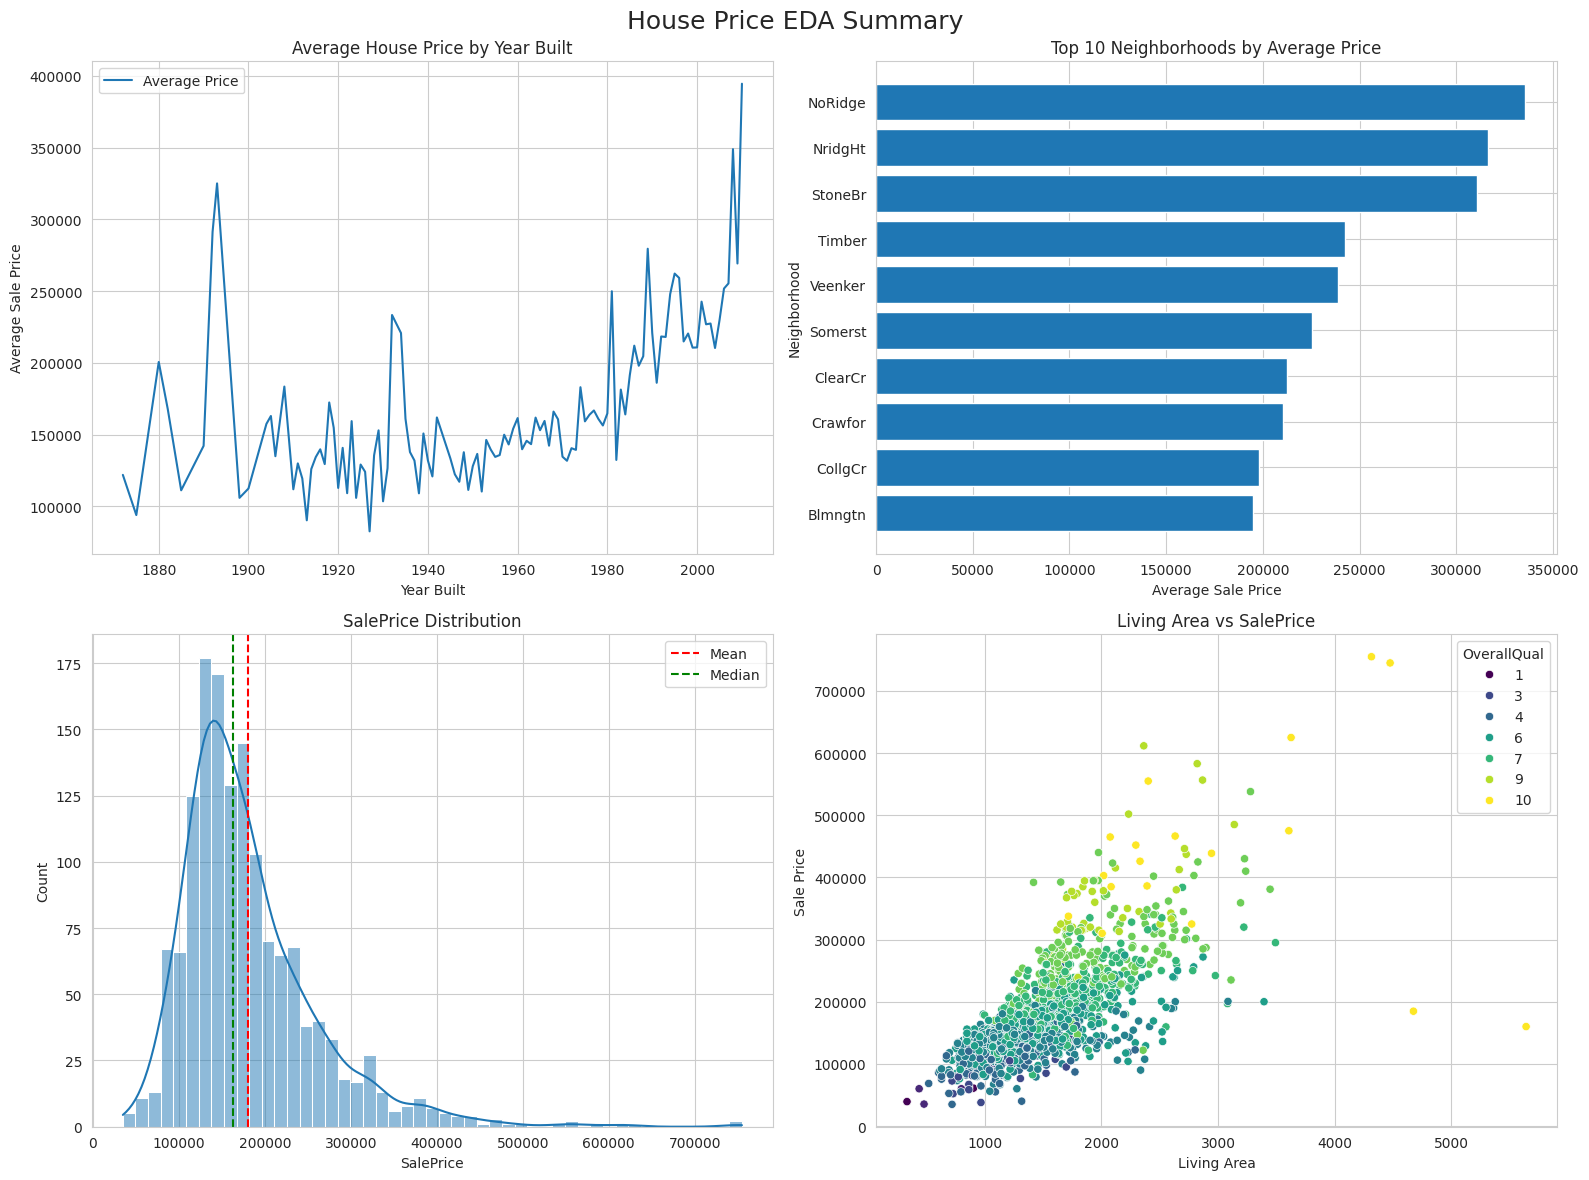

Dashboard created and saved successfully!


In [33]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Average SalePrice by YearBuilt
year_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    year_price.index,
    year_price.values,
    label="Average Price"
)

axes[0, 0].set_title("Average House Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()

# Panel 2: Top 10 Neighborhoods
neighborhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

axes[0, 1].barh(
    neighborhood_price.index[::-1],
    neighborhood_price.values[::-1]
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: SalePrice Distribution
sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].axvline(
    df["SalePrice"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    df["SalePrice"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].legend()

# Panel 4: Living Area vs SalePrice
sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs SalePrice")
axes[1, 1].set_xlabel("Living Area")
axes[1, 1].set_ylabel("Sale Price")

# Final dashboard title
fig.suptitle(
    "House Price EDA Summary",
    fontsize=18
)

plt.tight_layout()

# Save dashboard
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()

print("Dashboard created and saved successfully!")



# 12. Conclusion

In this project, we performed Exploratory Data Analysis on the Ames Housing Dataset using Python.

We studied house prices, analysed numerical and categorical variables, calculated descriptive statistics, identified missing values and detected outliers.

The analysis helped us understand the relationship between house features and sale prices.

### Key Findings

1. SalePrice distribution was analysed using histograms and boxplots.
2. OverallQual and GrLivArea were examined to understand their relationship with house prices.
3. House prices were compared across different neighborhoods.
4. Missing values were handled using suitable methods.
5. Outliers were identified using IQR and Z-score methods.
6. Different visualizations were created to understand the dataset.

### Final Result

This project helped us understand how Exploratory Data Analysis can be used to study real-world datasets, identify patterns and discover useful insights without using machine learning.
